In [1]:
!pip install -U 'skorch[pytorch]' && pip install -q -U faiss-gpu-cu12


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
try:
    import xgboost
except:
    !pip install xgboost
    import xgboost

try:
    import lightgbm
except:
    !pip install lightgbm
    import lightgbm

try:
    import catboost
except:
    !pip install catboost
    import catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 34.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 252.4/252.4 MB 35.3 MB/s eta 0:00:0000:0100:01

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 37.1 MB/s eta 0:00:00

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 33.1 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 67.8 MB/s eta 0:00:00

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [3]:
try:
    from pytabkit import (
            RealMLP_TD_Classifier,
            TabM_D_Classifier,
            Resnet_RTDL_D_Classifier,
            MLP_RTDL_D_Classifier,
            MLP_PLR_D_Classifier,
            TabR_S_D_Classifier,
            FTT_D_Classifier,
            XGB_TD_Classifier,
            LGBM_TD_Classifier,
            CatBoost_TD_Classifier,
    )
except:
    !pip install pytabkit
    from pytabkit import (
            RealMLP_TD_Classifier,
            TabM_D_Classifier,
            Resnet_RTDL_D_Classifier,
            MLP_RTDL_D_Classifier,
            MLP_PLR_D_Classifier,
            TabR_S_D_Classifier,
            FTT_D_Classifier,
            XGB_TD_Classifier,
            LGBM_TD_Classifier,
            CatBoost_TD_Classifier,
    )

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 852.4/852.4 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 28.7 MB/s eta 0:00:00

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


/usr/local/lib/python3.12/site-packages/torch_xla/__init__.py:258: UserWarning: `tensorflow` can conflict with `torch-xla`. Prefer `tensorflow-cpu` when using PyTorch/XLA. To silence this warning, `pip uninstall -y tensorflow && pip install tensorflow-cpu`. If you are in a notebook environment such as Colab or Kaggle, restart your notebook runtime afterwards.
  warnings.warn(


In [4]:
# try:
#     from venn_abers import VennAbersCalibrator
#     # from cir_model import CenteredIsotonicRegression
# except:
#     !pip install venn-abers
#     from venn_abers import VennAbersCalibrator
#     # from cir_model import CenteredIsotonicRegression

In [5]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'CPU: 224'

In [1]:
import numpy as np, pandas as pd, random
import matplotlib.pyplot as plt, seaborn as sns

import itertools
from tqdm import tqdm
from time import time, sleep

from sklearn.utils.class_weight import compute_class_weight
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split

from sklearn.metrics import roc_auc_score, log_loss, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.preprocessing import (
                StandardScaler, KBinsDiscretizer,
                OneHotEncoder, LabelEncoder, label_binarize,
                TargetEncoder as sklearnTE,
)

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Set Configuration --
# sklearn.set_config(transform_output="pandas")
# pd.options.mode.copy_on_write = True
pd.set_option("display.max_columns", 1000)
sns.set_style("whitegrid")
# plt.style.use('ggplot')

warnings

<module 'warnings' from '/usr/lib/python3.13/warnings.py'>

In [2]:
# plt.rcParams['axes.prop_cycle'] = cycler(color=['red', 'green', 'blue'])
plt.rcParams.update({
    # "figure.facecolor": '#0f0f1a', # Outer panel (figure)
    # "axes.facecolor":   '#1a1a2e', # Inner panel (image)
    # "axes.edgecolor":   '#444466',
    # "axes.labelcolor":  '#e0e0ff',
    # "text.color":       'lightblue',
    # "xtick.color":      '#e0e0ff',
    # "ytick.color":      '#e0e0ff',
    # "grid.color":       '#2a2a4a',
    # "grid.alpha":       0.5,
    "font.family":      'monospace',
})

PALETTE = ['c', 'r', 'darkorange', '#3A86FF', 'y']
sns.set_palette(PALETTE)
cmap = sns.diverging_palette(0, 230, 90, 60, as_cmap=True)

## -- Set Global Seed --
CFG = {
    'FOLDS':   5,
    'SEED':    42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [ ]:
def seed_everything(seed):
    print(f"🌱 Seeding everything ({seed})")
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything(seed=CFG['SEED'])

## Load Data

In [9]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e8/"
    submit = pd.read_csv(PATH+'sample_submission.csv')
    train = pd.read_csv(PATH+'train.csv')
    test = pd.read_csv(PATH+'test.csv')

    ORIG_PATH = "/kaggle/input/datasets/jimarahman/smartphone-usage-and-addiction-analysis-dataset/"
    orig = pd.read_csv(ORIG_PATH+"Smartphone_Usage_And_Addiction_Analysis_7500_Rows.csv")
elif PLATFORM == 'colab':
    from google.colab import drive
    drive.mount('/content/drive')

    PATH = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e8 | Phone Addiction/_phone_addiction_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")
    orig = pd.read_csv(PATH+"Smartphone_Usage_And_Addiction_Analysis_7500_Rows.csv")

## ----------------------------------------------------------------------------------

ID      = "id"
TARGET  = "addicted_label"
OBJECTS = train.select_dtypes(include=["object", "category"]).columns.tolist()

CATS = [c for c in OBJECTS if c not in [TARGET, ID]]
NUMS = [c for c in train.columns if c not in CATS+[TARGET, ID]]
BASE = NUMS + CATS

for (name, df) in {"Train": train, "Test": test, "Orig": orig}.items():
    print(f"{name} shape: {df.shape}")

print(f"\nTotal Numerical: {len(NUMS)}")
print(f"Total Categorical: {len(CATS)}")
print(f"Total base features: {len(BASE)}")

Train shape: (691369, 14)
Test shape: (296302, 13)
Orig shape: (7500, 16)

Total Numerical: 9
Total Categorical: 3
Total base features: 12


In [10]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
id,691369.0,345684.000000,199581.183467,0.00,172842.00,345684.00,518526.00,691368.00
age,662440.0,26.615408,5.153162,18.00,22.00,27.00,31.00,35.00
daily_screen_time_hours,595515.0,7.640865,2.721446,0.50,5.48,7.77,9.84,15.00
social_media_hours,557374.0,2.471038,1.316137,0.00,1.45,2.31,3.37,8.00
gaming_hours,564548.0,1.459265,0.934552,0.00,0.70,1.33,2.09,4.00
work_study_hours,639851.0,2.366971,1.258797,0.00,1.36,2.20,3.20,6.00
sleep_hours,646889.0,6.804334,1.234512,4.50,5.78,6.80,7.87,9.00
notifications_per_day,623785.0,145.894900,65.917556,20.00,93.00,150.00,204.00,250.00
app_opens_per_day,610659.0,102.636781,48.093970,15.00,64.00,104.00,145.00,180.00
weekend_screen_time,579306.0,9.479866,2.856006,0.51,7.28,9.58,11.75,17.56


## Preprocess Features

In [11]:
## -- Helper functions --
def get_class_weights(y):
    """
    y: Current y_labels -> numpy array or series
    """
    cls_ = np.unique(y)
    wts_ = compute_class_weight("balanced", classes=cls_, y=y)
    return dict(zip(cls_, wts_))

def get_sample_weights(y, y_true, opt='auto'):
    """
    y: Current y_labels -> numpy array or series
    y_true: True labels -> numpy array or series
    opt: 'auto' generate weight or pass a custom dict -> label: weight
    """
    if opt != 'auto':
        return np.array([opt[label] for label in y])
    else:
        cls_ = np.unique(y_true)
        wts_ = compute_class_weight('balanced', classes=cls_, y=y_true)
        cls_wts = dict(zip(cls_, wts_))
        return np.array([cls_wts[label] for label in y])

print("- Helper functions ready -")

- Helper functions ready -


In [12]:
def apply_feature_engineering(df_, num_features_, cat_features_):
    df = df_.copy()

    num_to_cat = []
    for col in num_features_:
        cat_name = f"{col}_cat"
        df[cat_name] = df[col].factorize()[0]
        num_to_cat.append(cat_name)

    for c in num_features_:
        for i in [0, 1]:
            df[f"{c}_round{i}"] = df[c].round(i)

    social = df['social_media_hours']
    gaming = df['gaming_hours']
    work = df['work_study_hours']
    daily = df['daily_screen_time_hours']
    sleep = df['sleep_hours']
    weekend = df['weekend_screen_time']
    opens = df['app_opens_per_day']
    notifications = df['notifications_per_day']

    df['total_breakdown_hours'] = social.fillna(0) + gaming.fillna(0) + work.fillna(0)
    df['social_ratio'] = social / (daily + 1e-5)
    df['gaming_ratio'] = gaming / (daily + 1e-5)
    df['work_ratio'] = work / (daily + 1e-5)
    df['unaccounted_screen_time'] = daily - df['total_breakdown_hours']
    df['screen_to_sleep_ratio'] = daily / (sleep + 1e-5)
    df['weekend_vs_daily_ratio'] = weekend / (daily + 1e-5)
    df['app_opens_per_hour'] = opens / (daily + 1e-5)
    df['notifications_per_hour'] = notifications / (daily + 1e-5)

    COMP = ['social_media_hours', 'gaming_hours', 'work_study_hours']
    n_missing_components = df[COMP].isna().sum(axis=1)
    missing_daily = daily.isna()
    known_component_sum = df[COMP].sum(axis=1, min_count=1)
    slack = daily - known_component_sum
    daily_missing_with_components = missing_daily & (n_missing_components == 0)
    one_component_missing = (~missing_daily) & (n_missing_components == 1)
    all_screen_known = (~missing_daily) & (n_missing_components == 0)

    df['ci_daily_lb'] = np.where(daily_missing_with_components, known_component_sum, np.nan)
    df['ci_missing_comp_ub'] = np.where(one_component_missing, slack, np.nan)
    df['ci_missing_comp_mid'] = np.where(one_component_missing, np.clip(slack / 2, 0, None), np.nan)
    df['ci_interval_width'] = np.where(one_component_missing, slack, np.nan)
    df['ci_slack_exact'] = np.where(all_screen_known, slack, np.nan)
    df['ci_case'] = np.select([daily_missing_with_components, one_component_missing], [1.0, 2.0], default=0.0).astype('float32')
    df['ci_n_missing'] = (missing_daily.astype('int8') + n_missing_components).astype('float32')

    df['missing_count'] = df[num_features_+cat_features_].isna().sum(axis=1).astype('float32')

    drop = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
    if drop:
        df.drop(drop, axis=1, inplace=True)

    fe_cols = [c for c in df.columns if c not in BASE]

    if ID in fe_cols:
        fe_cols.remove(ID)
    if TARGET in fe_cols:
        fe_cols.remove(TARGET)

    return df, fe_cols 

train, FE_COLS  = apply_feature_engineering(train, NUMS, CATS)
test, _ = apply_feature_engineering(test, NUMS, CATS)
orig, _ = apply_feature_engineering(orig, NUMS, CATS)

new_cats = [c for c in FE_COLS if c.endswith("_cat")]

# new_cats = ["missing_count", "ci_case", "ci_n_missing"]
# new_cats.extend([
#     c for c in FE_COLS
#     if "_round" in c
#     or c.endswith("_cat")
#     or c.startswith("ci_")
# ])

new_nums = [c for c in FE_COLS if c not in new_cats]

# CATS.extend(new_cats)
# NUMS.extend(new_nums)

display(train[FE_COLS].head())

train[FE_COLS].nunique().sort_values()


,age_cat,daily_screen_time_hours_cat,social_media_hours_cat,gaming_hours_cat,work_study_hours_cat,sleep_hours_cat,notifications_per_day_cat,app_opens_per_day_cat,weekend_screen_time_cat,age_round0,age_round1,daily_screen_time_hours_round0,daily_screen_time_hours_round1,social_media_hours_round0,social_media_hours_round1,gaming_hours_round0,gaming_hours_round1,work_study_hours_round0,work_study_hours_round1,sleep_hours_round0,sleep_hours_round1,notifications_per_day_round0,notifications_per_day_round1,app_opens_per_day_round0,app_opens_per_day_round1,weekend_screen_time_round0,weekend_screen_time_round1,total_breakdown_hours,social_ratio,gaming_ratio,work_ratio,unaccounted_screen_time,screen_to_sleep_ratio,weekend_vs_daily_ratio,app_opens_per_hour,notifications_per_hour,ci_daily_lb,ci_missing_comp_ub,ci_missing_comp_mid,ci_interval_width,ci_slack_exact,ci_case,ci_n_missing,missing_count
0,0,-1,0,0,0,0,0,0,0,24.0,24.0,NaN,NaN,2.0,1.8,2.0,1.6,2.0,2.1,7.0,7.5,122.0,122.0,38.0,38.0,9.0,8.6,5.53,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.53,NaN,NaN,NaN,NaN,1.0,1.0,1.0
1,1,0,1,-1,1,1,1,1,-1,19.0,19.0,6.0,6.0,1.0,1.1,NaN,NaN,3.0,3.0,8.0,8.2,76.0,76.0,19.0,19.0,NaN,NaN,4.11,0.180904,NaN,0.507537,1.86,0.726276,NaN,3.182574,12.730297,NaN,1.86,0.93,1.86,NaN,2.0,1.0,2.0
2,2,1,-1,-1,-1,2,2,2,1,18.0,18.0,5.0,5.1,NaN,NaN,NaN,NaN,NaN,NaN,6.0,6.2,134.0,134.0,60.0,60.0,7.0,7.5,0.00,NaN,NaN,NaN,5.09,0.814399,1.467581,11.787796,26.326078,NaN,NaN,NaN,NaN,NaN,0.0,3.0,3.0
3,3,2,2,1,2,3,3,3,2,21.0,21.0,6.0,6.4,1.0,1.3,1.0,1.4,3.0,3.4,9.0,8.8,112.0,112.0,94.0,94.0,9.0,8.7,6.04,0.196261,0.221183,0.523364,0.38,0.725423,1.348908,14.641722,17.445456,NaN,NaN,NaN,NaN,0.38,0.0,0.0,1.0
4,4,3,3,2,3,4,-1,-1,3,26.0,26.0,11.0,11.2,2.0,1.9,3.0,2.8,2.0,2.0,5.0,5.2,NaN,NaN,NaN,NaN,13.0,13.4,6.63,0.166964,0.250893,0.174107,4.57,2.133329,1.195535,NaN,NaN,NaN,NaN,NaN,NaN,4.57,0.0,0.0,2.0


ci_case                                3
gaming_hours_round0                    5
ci_n_missing                           5
sleep_hours_round0                     6
work_study_hours_round0                7
social_media_hours_round0              9
missing_count                         12
daily_screen_time_hours_round0        16
age_round1                            18
weekend_screen_time_round0            18
age_round0                            18
age_cat                               19
gaming_hours_round1                   41
sleep_hours_round1                    46
work_study_hours_round1               61
social_media_hours_round1             81
daily_screen_time_hours_round1       146
app_opens_per_day_round0             166
app_opens_per_day_round1             166
weekend_screen_time_round1           167
app_opens_per_day_cat                167
notifications_per_day_round1         231
notifications_per_day_round0         231
notifications_per_day_cat            232
gaming_hours_cat

In [13]:
## -- Frequency encoding --
FREQ_COLS = []

print(f"\nCreating frequencies... ", end="")
for col in NUMS:
    freq = pd.concat([train[col], test[col], orig[col]]).value_counts(dropna=False, normalize=True) #
    n = f"{col}_FREQ"
    print(n+", ", end="")
    for df in [train, test, orig]:
        df[n] = df[col].map(freq).fillna(0).astype("float32")
    FREQ_COLS.append(n)

print(f"\n✓ Total frequency features: {len(FREQ_COLS)}")

train[NUMS+FREQ_COLS]


Creating frequencies... age_FREQ, daily_screen_time_hours_FREQ, social_media_hours_FREQ, gaming_hours_FREQ, work_study_hours_FREQ, sleep_hours_FREQ, notifications_per_day_FREQ, app_opens_per_day_FREQ, weekend_screen_time_FREQ, 
✓ Total frequency features: 9


,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,age_FREQ,daily_screen_time_hours_FREQ,social_media_hours_FREQ,gaming_hours_FREQ,work_study_hours_FREQ,sleep_hours_FREQ,notifications_per_day_FREQ,app_opens_per_day_FREQ,weekend_screen_time_FREQ
0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,0.046406,0.129266,0.002680,0.002655,0.004208,0.004194,0.005188,0.007454,0.002292
1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,0.049082,0.001613,0.001716,0.187145,0.001559,0.000855,0.007745,0.005633,0.163550
2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,0.047898,0.000713,0.182272,0.187145,0.079680,0.005797,0.002166,0.004077,0.001595
3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,0.057899,0.000820,0.002494,0.002573,0.002378,0.002358,0.008818,0.005310,0.000615
4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,0.054907,0.000480,0.003234,0.001878,0.002928,0.002653,0.102299,0.106931,0.000533
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
691364,22.0,10.78,3.25,1.57,1.65,7.71,86.0,94.0,12.89,0.048841,0.000917,0.002738,0.003255,0.003730,0.003061,0.002960,0.005310,0.001807
691365,20.0,3.45,1.86,0.89,0.30,6.59,221.0,42.0,8.47,0.054722,0.001172,0.003309,0.002263,0.000501,0.003874,0.005318,0.009931,0.002690
691366,NaN,NaN,NaN,NaN,2.06,6.16,NaN,86.0,7.79,0.046291,0.129266,0.182272,0.187145,0.003060,0.001770,0.102299,0.002160,0.001274
691367,22.0,11.78,3.69,0.23,1.35,5.53,171.0,62.0,7.71,0.048841,0.001420,0.001785,0.002101,0.003872,0.001106,0.002876,0.002794,0.001712


In [14]:
# ## -- Cyclic encoding --
# CYCLICS = []
# cy_cols = [c for c in train.columns if c.endswith("_hours")]

# for col in tqdm(cy_cols):
#     for p in [12, 24]:
#         n_s = f"{col}_sin_{p}"

#         train[n_s] = np.sin(2 * np.pi * train[col] / p).astype('float32')
#         orig[n_s]  = np.sin(2 * np.pi * orig[col] / p).astype('float32')
#         test[n_s]  = np.sin(2 * np.pi * test[col] / p).astype('float32')
#         CYCLICS.append(n_s)

#         # n_c = f"{col}_cos_{p}"
#         # train[n_c] = np.cos(2 * np.pi * train[col] / p).astype('float32')
#         # test[n_c] = np.cos(2 * np.pi * test[col] / p).astype('float32')
#         # orig[n_c] = np.cos(2 * np.pi * orig[col] / p).astype('float32')
#         # CYCLICS.append(n_c)

# # NUMS.extend(CYCLICS)

# print(f"Cylcic Features created: {len(CYCLICS)}")
# print(train[CYCLICS].describe().T)

# train[CYCLICS].head()

In [15]:
# ## -- Get NaN indicators --
# def appy_nan_indicator(df):
#     df1 = df.copy()
#     cols_with_nan = df1.columns[df1.isna().any()]
#     indicators = df1[cols_with_nan].isna().astype(float).add_prefix('isna_')
#     indi_cols = indicators.columns.tolist()
#     df1 = df1.join(indicators)

#     return df1, indi_cols

# train, INDI_COLS = appy_nan_indicator(train)
# test, _  = appy_nan_indicator(test)
# orig, _  = appy_nan_indicator(orig)

# ## -- Fill categorical --
# train[CATS] = train[CATS].fillna('missing')
# test[CATS]  = test[CATS].fillna('missing')
# orig[CATS]  = orig[CATS].fillna('missing')

# print(INDI_COLS)
# train

In [16]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/CategoryMean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f"TE_{col}_{agg_func}"
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f"TE_{col}_{agg_func}"

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}
        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)
        return X

In [17]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    pbar = tqdm(valid_features)
    for col in pbar:
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"
            pbar.set_description(f"Augmenting {col}")
            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df, on=col, how='left')

            orig_cols.append(new_col)

        pbar.set_description(f"Original augment complete!")

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if c.endswith(('_mean', '_max', '_min')):
                df[c] = df[c].fillna(global_mean)
            elif c.endswith('_median'):
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


In [18]:
# ## -- "mean", "median", "count", "std", "skew", "nunique", "max", "min"
# orig_aggs = ["mean", "count"]

# train, orig_cols = original_TE(
#     orig,
#     train,
#     features=BASE,
#     target=TARGET,
#     aggs=orig_aggs,
#     fill_nan=True,
# )

# test, _ = original_TE(
#     orig,
#     test,
#     features=BASE,
#     target=TARGET,
#     aggs=orig_aggs,
#     fill_nan=True,
# )

# train[orig_cols][:10].T

In [19]:
FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Total Features:", len(FEATURES))

combined = pd.concat([train, test, orig])
combined[CATS] = combined[CATS].fillna("_empty_")
## ------------------------------------------------------------
# # -- Duplicate Nums as Cats --
# CATS_2 = []
# for c in tqdm(NUMS, title="nums_to_cats"):
#     n = f"{c}_cat"
#     combined[n] = combined[c].copy()
#     CATS_2.append(n)
# FEATURES.extend(CATS_2)
## ------------------------------------------------------------
# ## -- Factorize CATS --
# for c in tqdm(CATS, desc="factorize_cats"): # +INTER + new_cats
#     combined[c] = combined[c].factorize()[0]

# for c in tqdm(CATS, desc="categorize_cats"):
#     combined[c] = combined[c].astype("category")

train = combined.iloc[:len(train)][FEATURES+[TARGET]]
test  = combined.iloc[len(train):len(train)+len(test)][FEATURES]
orig  = combined.iloc[len(train)+len(test):]

del combined
print("Label encoding complete!")

train

Total Features: 65
Label encoding complete!


,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,age_cat,daily_screen_time_hours_cat,social_media_hours_cat,gaming_hours_cat,work_study_hours_cat,sleep_hours_cat,notifications_per_day_cat,app_opens_per_day_cat,weekend_screen_time_cat,age_round0,age_round1,daily_screen_time_hours_round0,daily_screen_time_hours_round1,social_media_hours_round0,social_media_hours_round1,gaming_hours_round0,gaming_hours_round1,work_study_hours_round0,work_study_hours_round1,sleep_hours_round0,sleep_hours_round1,notifications_per_day_round0,notifications_per_day_round1,app_opens_per_day_round0,app_opens_per_day_round1,weekend_screen_time_round0,weekend_screen_time_round1,total_breakdown_hours,social_ratio,gaming_ratio,work_ratio,unaccounted_screen_time,screen_to_sleep_ratio,weekend_vs_daily_ratio,app_opens_per_hour,notifications_per_hour,ci_daily_lb,ci_missing_comp_ub,ci_missing_comp_mid,ci_interval_width,ci_slack_exact,ci_case,ci_n_missing,missing_count,age_FREQ,daily_screen_time_hours_FREQ,social_media_hours_FREQ,gaming_hours_FREQ,work_study_hours_FREQ,sleep_hours_FREQ,notifications_per_day_FREQ,app_opens_per_day_FREQ,weekend_screen_time_FREQ,addicted_label
0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,0,-1,0,0,0,0,0,0,0,24.0,24.0,NaN,NaN,2.0,1.8,2.0,1.6,2.0,2.1,7.0,7.5,122.0,122.0,38.0,38.0,9.0,8.6,5.53,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.53,NaN,NaN,NaN,NaN,1.0,1.0,1.0,0.046406,0.129266,0.002680,0.002655,0.004208,0.004194,0.005188,0.007454,0.002292,1.0
1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,1,0,1,-1,1,1,1,1,-1,19.0,19.0,6.0,6.0,1.0,1.1,NaN,NaN,3.0,3.0,8.0,8.2,76.0,76.0,19.0,19.0,NaN,NaN,4.11,0.180904,NaN,0.507537,1.86,0.726276,NaN,3.182574,12.730297,NaN,1.86,0.93,1.86,NaN,2.0,1.0,2.0,0.049082,0.001613,0.001716,0.187145,0.001559,0.000855,0.007745,0.005633,0.163550,0.0
2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,2,1,-1,-1,-1,2,2,2,1,18.0,18.0,5.0,5.1,NaN,NaN,NaN,NaN,NaN,NaN,6.0,6.2,134.0,134.0,60.0,60.0,7.0,7.5,0.00,NaN,NaN,NaN,5.09,0.814399,1.467581,11.787796,26.326078,NaN,NaN,NaN,NaN,NaN,0.0,3.0,3.0,0.047898,0.000713,0.182272,0.187145,0.079680,0.005797,0.002166,0.004077,0.001595,0.0
3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,_empty_,3,2,2,1,2,3,3,3,2,21.0,21.0,6.0,6.4,1.0,1.3,1.0,1.4,3.0,3.4,9.0,8.8,112.0,112.0,94.0,94.0,9.0,8.7,6.04,0.196261,0.221183,0.523364,0.38,0.725423,1.348908,14.641722,17.445456,NaN,NaN,NaN,NaN,0.38,0.0,0.0,1.0,0.057899,0.000820,0.002494,0.002573,0.002378,0.002358,0.008818,0.005310,0.000615,1.0
4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,4,3,3,2,3,4,-1,-1,3,26.0,26.0,11.0,11.2,2.0,1.9,3.0,2.8,2.0,2.0,5.0,5.2,NaN,NaN,NaN,NaN,13.0,13.4,6.63,0.166964,0.250893,0.174107,4.57,2.133329,1.195535,NaN,NaN,NaN,NaN,NaN,NaN,4.57,0.0,0.0,2.0,0.054907,0.000480,0.003234,0.001878,0.002928,0.002653,0.102299,0.106931,0.000533,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
691364,22.0,10.78,3.25,1.57,1.65,7.71,86.0,94.0,12.89,Male,_empty_,No,12,783,374,145,109,88,168,3,786,22.0,22.0,11.0,10.8,3.0,3.2,2.0,1.6,2.0,1.6,8.0,7.7,86.0,86.0,94.0,94.0,13.0,12.9,6.47,0.301484,0.145640,0.153061,4.31,1.398182,1.195732,8.719843,7.977729,NaN,NaN,NaN,NaN,4.31,0.0,0.0,1.0,0.048841,0.000917,0.002738,0.003255,0.003730,0.003061,0.002960,0.005310,0.001807,1.0
691365,20.0,3.45,1.86,0.89,0.30,6.59,221.0,42.0,8.47,Female,High,No,7,342,163,82,248,312,102,77,154,20.0,20.0,3.0,3.4,2.0,1.9,1.0,0.9,0.0,0.3,7.0,6.6,221.0,221.0,42.0,42.0,8.0,8.5,3.05,0.539129,0.257970,0.086956,0.40,0.523520,2.455065,12.173878,64.057785,NaN,NaN,NaN,NaN,0.40,0.0,0.0,0.0,0.054722,0.001172,0.003309,0.002263,0.000501,0.003874,0.005318,0.009931,0

In [20]:
FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
FEATURES = list(set(FEATURES))

NEW_NUMS = [c for c in FEATURES if c not in CATS+new_cats]

print("Total Features:", len(FEATURES))

train

Total Features: 65


,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,age_cat,daily_screen_time_hours_cat,social_media_hours_cat,gaming_hours_cat,work_study_hours_cat,sleep_hours_cat,notifications_per_day_cat,app_opens_per_day_cat,weekend_screen_time_cat,age_round0,age_round1,daily_screen_time_hours_round0,daily_screen_time_hours_round1,social_media_hours_round0,social_media_hours_round1,gaming_hours_round0,gaming_hours_round1,work_study_hours_round0,work_study_hours_round1,sleep_hours_round0,sleep_hours_round1,notifications_per_day_round0,notifications_per_day_round1,app_opens_per_day_round0,app_opens_per_day_round1,weekend_screen_time_round0,weekend_screen_time_round1,total_breakdown_hours,social_ratio,gaming_ratio,work_ratio,unaccounted_screen_time,screen_to_sleep_ratio,weekend_vs_daily_ratio,app_opens_per_hour,notifications_per_hour,ci_daily_lb,ci_missing_comp_ub,ci_missing_comp_mid,ci_interval_width,ci_slack_exact,ci_case,ci_n_missing,missing_count,age_FREQ,daily_screen_time_hours_FREQ,social_media_hours_FREQ,gaming_hours_FREQ,work_study_hours_FREQ,sleep_hours_FREQ,notifications_per_day_FREQ,app_opens_per_day_FREQ,weekend_screen_time_FREQ,addicted_label
0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,0,-1,0,0,0,0,0,0,0,24.0,24.0,NaN,NaN,2.0,1.8,2.0,1.6,2.0,2.1,7.0,7.5,122.0,122.0,38.0,38.0,9.0,8.6,5.53,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.53,NaN,NaN,NaN,NaN,1.0,1.0,1.0,0.046406,0.129266,0.002680,0.002655,0.004208,0.004194,0.005188,0.007454,0.002292,1.0
1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,1,0,1,-1,1,1,1,1,-1,19.0,19.0,6.0,6.0,1.0,1.1,NaN,NaN,3.0,3.0,8.0,8.2,76.0,76.0,19.0,19.0,NaN,NaN,4.11,0.180904,NaN,0.507537,1.86,0.726276,NaN,3.182574,12.730297,NaN,1.86,0.93,1.86,NaN,2.0,1.0,2.0,0.049082,0.001613,0.001716,0.187145,0.001559,0.000855,0.007745,0.005633,0.163550,0.0
2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,2,1,-1,-1,-1,2,2,2,1,18.0,18.0,5.0,5.1,NaN,NaN,NaN,NaN,NaN,NaN,6.0,6.2,134.0,134.0,60.0,60.0,7.0,7.5,0.00,NaN,NaN,NaN,5.09,0.814399,1.467581,11.787796,26.326078,NaN,NaN,NaN,NaN,NaN,0.0,3.0,3.0,0.047898,0.000713,0.182272,0.187145,0.079680,0.005797,0.002166,0.004077,0.001595,0.0
3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,_empty_,3,2,2,1,2,3,3,3,2,21.0,21.0,6.0,6.4,1.0,1.3,1.0,1.4,3.0,3.4,9.0,8.8,112.0,112.0,94.0,94.0,9.0,8.7,6.04,0.196261,0.221183,0.523364,0.38,0.725423,1.348908,14.641722,17.445456,NaN,NaN,NaN,NaN,0.38,0.0,0.0,1.0,0.057899,0.000820,0.002494,0.002573,0.002378,0.002358,0.008818,0.005310,0.000615,1.0
4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,4,3,3,2,3,4,-1,-1,3,26.0,26.0,11.0,11.2,2.0,1.9,3.0,2.8,2.0,2.0,5.0,5.2,NaN,NaN,NaN,NaN,13.0,13.4,6.63,0.166964,0.250893,0.174107,4.57,2.133329,1.195535,NaN,NaN,NaN,NaN,NaN,NaN,4.57,0.0,0.0,2.0,0.054907,0.000480,0.003234,0.001878,0.002928,0.002653,0.102299,0.106931,0.000533,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
691364,22.0,10.78,3.25,1.57,1.65,7.71,86.0,94.0,12.89,Male,_empty_,No,12,783,374,145,109,88,168,3,786,22.0,22.0,11.0,10.8,3.0,3.2,2.0,1.6,2.0,1.6,8.0,7.7,86.0,86.0,94.0,94.0,13.0,12.9,6.47,0.301484,0.145640,0.153061,4.31,1.398182,1.195732,8.719843,7.977729,NaN,NaN,NaN,NaN,4.31,0.0,0.0,1.0,0.048841,0.000917,0.002738,0.003255,0.003730,0.003061,0.002960,0.005310,0.001807,1.0
691365,20.0,3.45,1.86,0.89,0.30,6.59,221.0,42.0,8.47,Female,High,No,7,342,163,82,248,312,102,77,154,20.0,20.0,3.0,3.4,2.0,1.9,1.0,0.9,0.0,0.3,7.0,6.6,221.0,221.0,42.0,42.0,8.0,8.5,3.05,0.539129,0.257970,0.086956,0.40,0.523520,2.455065,12.173878,64.057785,NaN,NaN,NaN,NaN,0.40,0.0,0.0,0.0,0.054722,0.001172,0.003309,0.002263,0.000501,0.003874,0.005318,0.009931,0

## Config

In [30]:
realmlp = RealMLP_TD_Classifier(**{
    ## --- Model architecture ---
    'n_ens': 8, 
    'embedding_size': 8,
    # 'max_one_hot_cat_size': 8,
    'hidden_sizes': [512, 512, 512],
    'p_drop': 0.06,
    'p_drop_sched': "flat_cos",
    'act': 'selu', # 🔥
    'act_lr_factor': 0.5,
    'add_front_scale': True,

    ## --- PBLD (periodic) embedding for numericals ---
    'num_emb_type': 'pbld',
    'plr_hidden_1': 16,
    'plr_hidden_2': 8,
    'plr_sigma': 5.0,
    'plr_lr_factor': 0.093,
    'plr_act_name': 'prelu',

    ## --- Optimizer ---
    'lr': 0.02, # 🔥
    'mom': 0.9,
    'sq_mom': 0.98, 
    'lr_sched': 'flat_cos',
    'wd': 0.012,
    'first_layer_lr_factor': 1.0,
    'weight_lr_factor': 0.5,

    ## --- Label smoothing ---
    'ls_eps': 0.04,
    'ls_eps_sched': "cos", #'cos', "coslog4"

    ## --- Processing ---
    'tfms': ['median_center', 'robust_scale'],

    ## --- Training loop ---
    'n_epochs': 20,
    'batch_size': 256,
    'predict_batch_size': 10240,
    'verbosity': 2,

    ## --- Early stopping ---
    'use_early_stopping': True,
    'early_stopping_additive_patience': 5,
    'early_stopping_multiplicative_patience': 1,
    
    # 'bias_init_mode': 'neg-uniform-dynamic-2', # def='he+5', # 'neg-uniform-dynamic-2',
    
    # 'device': 'cuda',
    'random_state': CFG['SEED'],
    'val_metric_name': "1-auc_ovr",
})

tabm = TabM_D_Classifier(**{
    'arch_type': "tabm-mini-normal",
    'num_emb_type': 'pwl',
    # 'allow_amp': True,
    'lr': 0.002, # 🔥
    # 'batch_size': 256,
    # 'd_block': 512,
    'n_epochs': 20,
    'patience': 3,
    'n_blocks': 3,
    'd_embedding': 16,
    # 'dropout': 0.05,
    # 'weight_decay': 0.01,
    # 'tabm_k': 24, # 32
    # 'num_emb_n_bins': 24,
    # 'gradient_clipping_norm': 1.0,
    'verbosity': 2,
    'random_state': CFG['SEED'],
    'device': "cuda" if torch.cuda.is_available() else "cpu",
    'val_metric_name': "1-auc_ovr",
})

mlp_plr = MLP_PLR_D_Classifier(**{
    'batch_size': 256,
    'max_epochs': 50,
    'es_patience': 5,
    'lr': 0.002, # 🔥
    # # 'lr_patience': 5,
    # # 'lr_scheduler': False,
    'module_d_embedding': 8,
    # # 'module_d_first_layer': 128,
    # # 'module_d_last_layer': 128,
    'module_d_layers': [512, 256, 64],
    'module_n_layers': 3,
    'module_dropout': 0.06,
    # 'module_num_emb_dim': 8,
    # 'module_num_emb_hidden_dim': 20,
    # 'n_threads': os.cpu_count(),
    'verbose': 2,
    'random_state': CFG['SEED'],
})

mlp_rtd = MLP_RTDL_D_Classifier(**{
    'batch_size': 256,
    'max_epochs': 50,
    'es_patience': 5,
    'lr': 0.02, # 🔥
    # # 'lr_patience': 30,
    # # 'lr_scheduler': False,
    'module_n_layers': 3,
    'module_d_embedding': 8,
    # # 'module_d_first_layer': 128,
    # # 'module_d_last_layer': 128,
    # 'module_d_layers': [512, 512, 512],
    # 'module_dropout': 0.06,
    'verbose': 2,
    'random_state': CFG['SEED'],
})

resnet_rtd = Resnet_RTDL_D_Classifier(**{
    'batch_size': 256,
    'max_epochs': 50,
    'es_patience': 5,
    'lr': 0.002, # 🔥
    # -------------------------------
    'module_activation': 'selu',
    'module_d': 512,
    'module_n_layers': 3,
    'module_d_embedding': 8,
    # -------------------------------
    # 'lr_scheduler': False,
    # 'lr_patience': 30,
    # -------------------------------
    # 'module_d_hidden_factor': 2,
    'module_hidden_dropout': 0.2,
    'module_residual_dropout': 0.2,
    'optimizer_weight_decay': 0.012,
    'verbose': 2,
    'random_state': CFG['SEED'],
})

xgb_m = XGB_TD_Classifier(**{
    'n_estimators': 20_000,
    # 'max_depth': 6,
    'lr': 0.01,
    'subsample': 0.9,
    'colsample_bytree': 0.6,
    # 'colsample_bylevel': 0.75,
    'alpha': 3.0,
    'reg_lambda': 10.0,
    'min_child_weight': 40,
    # 'max_bin': 1015,
    # 'max_cat_to_onehot': 10,
    # 'verbosity': 0,
    'random_state': CFG['SEED'],
    # 'n_threads': os.cpu_count(),
    'val_metric_name': "1-auc_ovr",
})

cat_bayes = CatBoost_TD_Classifier(**{
    'bootstrap_type': "Bayesian",
    'n_estimators': 20_000,
    # 'max_depth': 5,
    'lr': 0.03,
    'l2_leaf_reg': 0.1,
    # 'leaf_estimation_iterations': 5,
    'bagging_temperature': 0.4,
    'random_strength': 0.6,
    'one_hot_max_size': 10,
    'verbosity': 0,
    'random_state': CFG['SEED'],
    # "n_threads": os.cpu_count(),
})

cat_ben = CatBoost_TD_Classifier(**{
    'bootstrap_type': "Bernoulli",
    'n_estimators': 20_000,
    # 'max_depth': 6,
    'lr': 0.03,
    'subsample': 0.66,
    'l2_leaf_reg': 0.1,
    'random_strength': 0.6,
    'one_hot_max_size': 10,
    'verbosity': 0,
    'random_state': CFG['SEED'],
    # "n_threads": os.cpu_count(),
})

lgb_m = LGBM_TD_Classifier(**{
    'n_estimators': 20_000,
    'num_leaves': 80,
    'lr': 0.01, # 🔥
    # -------------------------------
    # 'max_bin': 600,
    'min_data_in_leaf': 80,
    # -------------------------------
    'colsample_bytree': 0.4,
    # 'subsample': 0.75,
    # 'bagging_freq': 2,
    'lambda_l1': 0.3,
    'lambda_l2': 3.0,
    'random_state': CFG['SEED'],
    'val_metric_name': "1-auc_ovr",
    # 'verbosity': 1,
    # 'n_threads': os.cpu_count(),
})

all_models = [
    # ('Pyrealmlp65', realmlp),     # GPU
    # ('Pytabm65', tabm),           # GPU
    # ('Pymlp_plr65', mlp_plr),     # GPU
    # ('Pymlp_rtd65', mlp_rtd),     # GPU
    # ('Pyresnet65', resnet_rtd),   # GPU
    ('Pyxgb65', xgb_m),           # GPU | TPU
    # ('Pycat_bayes65', cat_bayes), # TPU
    # ('Pycat_ben65', cat_ben),     # TPU
    # ('Pylgb65', lgb_m),           # CPU
]

print("🤖 Model parameters defined!")

all_models

🤖 Model parameters defined!


[('Pyxgb65',
  XGB_TD_Classifier(alpha=3.0, colsample_bytree=0.6, lr=0.01, min_child_weight=40,
                    n_estimators=20000, random_state=42, reg_lambda=10.0,
                    subsample=0.9, val_metric_name='1-auc_ovr'))]

In [31]:
# if USE_CALIBRATION:
#     ## -- Use calibration --
#     def Trainer_CV(model_name, base_model, X, y, X_ts, kfold, cat_cols, calibrator='iso'):
#         print(f"\n===== Starting CV: {model_name} =====")
#         start = time()

#         num_cls = y.nunique()
#         n_splits = kfold.n_splits
        
#         oof_preds  = np.zeros((len(X), num_cls))
#         test_preds = np.zeros((len(X_ts), num_cls))
#         fold_scores  = []

#         calib_oof_preds = np.zeros((len(X), num_cls))
#         calib_test_preds = np.zeros((len(X_ts), num_cls))
#         calib_fold_scores = []

#         for idx, (train_idx, val_idx) in enumerate(kfold.split(X, y), 1):
#             X_train, X_valid = X.iloc[train_idx], X.iloc[val_idx]
#             y_train, y_valid = y.iloc[train_idx], y.iloc[val_idx]
#             X_test = X_ts.copy()

#             print(f"\n##### FOLD {idx}/{n_splits} | Calibrate: True | shape: {X_train.shape}")
    
#             # ## -- OPTION A: Concatenate original data --
#             # X_train = pd.concat([X_train, orig[FEATURES]], ignore_index=True)
#             # y_train = np.concatenate([y_train, orig[TARGET].values], axis=0)
    
#             # ## -- OPTION B: TE Merge original data --
#             # X_train, X_valid, X_test, ORIG_COLS = orig_TE_data_propagate(
#             #     orig,
#             #     X_train,
#             #     X_valid,
#             #     X_test,
#             #     features=BASE,
#             #     target=TARGET,
#             #     aggs=['mean', 'std'], # mean, median, count, std, skew, nunique, max, min
#             #     # fill_nan=True,
#             # )
    
#             # CE_COLS = cats+ROUNDS
#             # print(f" • Cat_Mean Encoding {len(CE_COLS)} features...")
#             # cm_enc  = CategoryMeanTransformer(cat_cols=CE_COLS)
#             # X_train = cm_enc.fit_transform(X_train, y_train).fillna(-1)
#             # X_valid   = cm_enc.transform(X_valid).fillna(-1)
#             # X_test  = cm_enc.transform(X_test).fillna(-1)
    
#             # _, OPT_COLS, X_train, X_valid, X_test = _opt_multiclass_binning(
#             #     x_tr=X_train,
#             #     y_tr=y_train,
#             #     x_vl=X_valid,
#             #     x_ts=X_test,
#             #     bin_features=NUMS,
#             #     solver='cp', # 'cp', 'mip', 'lr'
#             #     metric='mean_woe', # 'mean_woe','weighted_mean_woe','indices','bins'
#             #     pre_bins=100,
#             #     # period=300,
#             # )
    
#             # combined = pd.concat([X_train, X_valid, X_test])
#             # for c in cats:
#             #     combined[c] = combined[c].astype(str).astype('category')
    
#             # X_train = combined.iloc[:len(X_train)]
#             # X_valid = combined.iloc[len(X_train):len(X_train)+len(X_valid)]
#             # X_test  = combined.iloc[len(X_train)+len(X_valid):]
    
#             ## -- Target Encoding --
#             te_cols = [col for col in cat_cols if not col.endswith('bin_')]
#             print(f" • Target Encoding {len(te_cols)} features... ")
#             X_train, X_valid, X_test = t_enc_multi(X_train, X_valid, X_test, y_train, te_cols, drop=True)
    
#             ## -- Internal Split for Calibration --
#             X_base, X_calib, y_base, y_calib = train_test_split(
#                 X_train, y_train, train_size=0.7, stratify=y_train, random_state=CFG['SEED']
#             )

#             print(f"Training {model_name} {X_base.shape}... ")
#             base_model.fit(X_base, y_base, X_valid, y_valid, cat_col_names=cat_cols)

#             oof_preds[val_idx] = base_model.predict_proba(X_valid)
#             test_preds += base_model.predict_proba(X_test)

#             fold_score = roc_auc_score(y_valid, oof_preds[val_idx])
#             fold_scores.append(fold_score)

#             # lb = LabelBinarizer()
#             # y_val_one_hot = lb.fit_transform(y_valid)

#             ## ----------------------------------------------------
#             ## -- Calibrate for "true" probabilities --
#             if calibrator == 'iso':
#                 print(f" • Calibrating isotonic {X_calib.shape}... ", end='')
#                 calib_model = CalibratedClassifierCV(
#                     FrozenEstimator(base_model), cv=None, method='isotonic', n_jobs=-1,
#                 )
#                 calib_model.fit(X_calib, y_calib, sample_weight=get_weights(y_calib, y_train))

#                 calib_oof_preds[val_idx] = calib_model.predict_proba(X_valid)
#                 calib_test_preds += calib_model.predict_proba(X_test)

#                 calib_fold_score = roc_auc_score(y_valid, calib_oof_preds[val_idx])
#                 calib_fold_scores.append(calib_fold_score)
#                 print(calib_oof_preds[val_idx].shape, calib_test_preds.shape)
#             elif calibrator == 'venn':
#                 print(f" • Calibrating Venn-Abers (1-vs-all) {X_calib.shape}... ", end='')

#                 vao = VennAbersCalibrator() # - Get OOF predictions --
#                 oof_calib = vao.predict_proba(p_cal=base_model.predict_proba(X_calib),
#                                               y_cal=y_calib.to_numpy(),
#                                               p_test=base_model.predict_proba(X_valid),
#                                               va_type='one_vs_all') # one_vs_one
#                 calib_oof_preds[val_idx] = oof_calib

#                 vat = VennAbersCalibrator() # - Get TEST predictions --
#                 test_calib = vat.predict_proba(p_cal=base_model.predict_proba(X_calib),
#                                                y_cal=y_calib.to_numpy(),
#                                                p_test=base_model.predict_proba(X_test),
#                                                va_type='one_vs_all') # one_vs_one
#                 calib_test_preds += test_calib

#                 calib_fold_score = roc_auc_score(y_valid, calib_oof_preds[val_idx])
#                 calib_fold_scores.append(calib_fold_score)
#                 print(oof_calib.shape, test_calib.shape)

#             base_loss  = log_loss(y_valid, oof_preds[val_idx])
#             calib_loss = log_loss(y_valid, calib_oof_preds[val_idx])

#             print(f"{CFG['YELLOW']} • Fold {idx} scores --------|")
#             print(f"base:  {fold_score:.5f} | loss: {base_loss:.5f}")
#             print(f"calib: {calib_fold_score:.5f} | loss: {calib_loss:.5f}{CFG['RESET']}")
#             ## ------------------------------------------------------------------------------

#         ## -- Average test predictions --
#         test_preds /= n_splits
#         calib_test_preds /= n_splits

#         ## -- Print final cross-validation results --
#         print("\n===================================")
#         print(f"{n_splits}-FOLDS CV: {model_name}")
#         print("===================================")
#         for i, (b, c) in enumerate(list(zip(fold_scores, calib_fold_scores)), 1):
#             print(f" • Fold {i} -> {model_name}: {b:.5f} | calib: {c:.5f}")
    
#         overall_score = np.round(roc_auc_score(y, oof_preds), 5)
#         calib_overall_score = np.round(roc_auc_score(y, calib_oof_preds), 5)
    
#         print(f"{'='*35}")
#         print(f"OOF base:  {overall_score}")
#         print(f"AVG base:  {np.mean(fold_scores):.5f} ± {np.std(fold_scores):.5f}")
#         print(f"{'-'*35}")
#         print(f"OOF calib: {calib_overall_score}")
#         print(f"AVG calib: {np.mean(calib_fold_scores):.5f} ± {np.std(calib_fold_scores):.5f}")
#         print(f"{'-'*35}")
#         print(f"{CFG['GREEN']}Diff: {calib_overall_score - overall_score:.5f}{CFG['RESET']}")
#         print(f"{'='*35}")
#         print(f"{((time() - start) / 60):.2f} mins\n")
    
#         return {
#             "scores": [overall_score, calib_overall_score],
#             # "models": base_model,
#             "oof_preds": [oof_preds, calib_oof_preds],
#             "test_preds": [test_preds, calib_test_preds],
#             "val_data": [X_valid, y_valid],
#         }
#     print("⚙️ Training calibration function ready ⚙️")
# else:
#     ## -- Train model --
#     def Trainer_CV(model_name, base_model, X, y, X_ts, kfold, cat_cols, calibrator=None):
#         print(f"\n===== Starting CV: {model_name} =====")
#         start = time()

#         num_cls = y.nunique()
#         n_splits = kfold.n_splits
    
#         oof_preds   = np.zeros((len(X), num_cls))
#         test_preds  = np.zeros((len(X_ts), num_cls))
#         fold_scores = []
#         brier_scores = []
    
#         for idx, (train_idx, val_idx) in enumerate(kfold.split(X, y), 1):
#             X_train, X_valid = X.iloc[train_idx], X.iloc[val_idx]
#             y_train, y_valid = y.iloc[train_idx], y.iloc[val_idx]
#             X_test = X_ts.copy()

#             print(f"\n##### FOLD {idx}/{n_splits} | Calibrate: False | Train shape: {X_train.shape}")

#             ## -- Target Encoding --
#             te_cols = [col for col in cat_cols if not col.endswith('bin_')]
#             print(f" • Target Encoding {len(te_cols)} features... ")
#             X_train, X_valid, X_test = t_enc_multi(X_train, X_valid, X_test, y_train, te_cols, drop=False)

#             print(f" • Training {model_name} | {X_train.shape}... ")
#             base_model.fit(X_train, y_train, X_valid, y_valid, cat_col_names=cat_cols)

#             oof_preds[val_idx] = base_model.predict_proba(X_valid)
#             test_preds += base_model.predict_proba(X_test)

#             fold_score = roc_auc_score(y_valid, oof_preds[val_idx])
#             fold_scores.append(fold_score)

#             brier_score = multi_class_brier(y_valid, oof_preds[val_idx], np.unique(y_valid))
#             brier_scores.append(brier_score)

#             print(f"{CFG['YELLOW']} • Fold {idx} acc: {fold_score:.5f} | brier: {brier_score:.5f}{CFG['RESET']}")
#             ## -------------------------------------------------------------------------

#         ## -- Average test predictions --
#         test_preds /= n_splits

#         ## -- CV results --
#         print("\n==================================================")
#         print(f"{n_splits}-FOLD CV: {model_name}")
#         print("==================================================")
#         for i, (a, b) in enumerate(zip(fold_scores, brier_scores), 1):
#             print(f" • Fold {i} score: {a:.5f} | brier: {b:.5f}")
    
#         ## -- Final out-of-fold score --
#         oof_score = np.round(roc_auc_score(y, oof_preds), 5)
#         oof_brier = np.round(multi_class_brier(y, oof_preds, np.unique(y)), 5)
    
#         print("-------------------------------------------------|")
#         print(f"OOF score: {oof_score}")
#         print(f"AVG score: {np.mean(fold_scores):.5f} ± {np.std(fold_scores):.5f}")
#         print("-------------------------------------------------|")
#         print(f"OOF brier: {oof_brier}")
#         print(f"AVG brier: {np.mean(brier_scores):.5f} ± {np.std(brier_scores):.5f}")
#         print("-------------------------------------------------|")
#         print(f'{((time() - start) / 60):.2f} mins')

#         # ## -- Print final cross-validation results --
#         # print("\n===================================")
#         # print(f"{n_splits}-FOLD CV: {model_name}")
#         # print("===================================")
#         # for i, s in enumerate(fold_scores, 1):
#         #     print(f" • Fold {i}: {s:.5f}")

#         # oof_score = np.round(roc_auc_score(y, oof_preds), 5)

#         # print(f"{'='*35}")
#         # print(f"OOF bal_acc: {overall_score}")
#         # print(f"AVG bal_acc: {np.mean(fold_scores):.5f} ± {np.std(fold_scores):.5f}")
#         # print(f"{'='*35}")
#         # print(f'{((time() - start) / 60):.2f} mins\n')

#         return {
#             'scores': oof_score,
#             'oof_preds': oof_preds,
#             'test_preds': test_preds,
#             'val_data': [X_valid, y_valid],
#             # 'models': base_model,
#         }

#     print("⚙️ Training raw model function ready ⚙️")

In [32]:
## -- Train model --
def Trainer_CV(model_name, model, X, y, X_ts, kfold, cat_cols=None, num_cols=None, use_original=False):
    print(f"\n===== Starting CV: {model_name} =====")
    t0 = time()

    n_splits = kfold.n_splits

    oof_preds  = np.zeros(len(X))
    test_preds = np.zeros(len(X_ts))

    fold_scores = []

    # Handle optional original table aggregations securely if flags enable them
    if use_original and "original_TE" in globals():
        feats = [*X.columns]
        # "mean", "count", "std", "skew"
        aggs_ = ["mean", "count"] 

        X_tr, orig_cols = original_TE(
            orig, X, target=TARGET, features=BASE, aggs=aggs_, fill_nan=True
        )
        x_test, _ = original_TE(
            orig, X_ts, target=TARGET, features=BASE, aggs=aggs_, fill_nan=True
        )
        feats.extend(orig_cols)
        X = X_tr[feats]
        # y = X_tr[target].astype("int8")
        X_ts = x_test[feats]
    # else:
    #     X = train_data[features]
    #     # y = train_data[target].astype("int8")
    #     X_ts = test[features]

    NEW_NUMS = [c for c in X.columns if c not in CATS+new_cats]

    for idx, (train_idx, val_idx) in enumerate(kfold.split(X, y), 1):
        print(f"\n+++++ FOLD {idx}/{n_splits}", end=" | ")
        
        X_train, X_valid = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_valid = y.iloc[train_idx], y.iloc[val_idx]
        X_test = X_ts.copy()

        ## -- TE Opt1. -> Using CUSTOM -- 
        te_enc  = customTE(new_cats, cv=5, smooth='auto', aggs=['mean'], drop_original=False)
        X_train = te_enc.fit_transform(X_train, y_train)
        X_valid = te_enc.transform(X_valid)
        X_test  = te_enc.transform(X_test)

        # --------------------------------------------------------------------
        # ---- Imputation ----
        
        # # Replace infinite values created by ratio features with NaN first, then fillna
        # X_train = X_train.replace([np.inf, -np.inf], np.nan).fillna(1e-6) #.astype("float32")
        # X_valid = X_valid.replace([np.inf, -np.inf], np.nan).fillna(1e-6) #.astype("float32")
        # X_test  = X_test.replace([np.inf, -np.inf], np.nan).fillna(1e-6) #.astype("float32")

        imputer = SimpleImputer() #.set_output(transform="pandas")
        X_train[num_cols] = imputer.fit_transform(X_train[num_cols], y_train)
        X_valid[num_cols] = imputer.transform(X_valid[num_cols])
        X_test[num_cols]  = imputer.transform(X_test[num_cols])

        print(X_train.shape)
        print("NaN values:", X_train.isna().sum().sum())
        if idx == 1:
            display(X_train.head())

        model.fit(X_train, y_train, X_valid, y_valid, cat_col_names=cat_cols)

        ## -- Predict on val/test --
        oof_preds[val_idx] = model.predict_proba(X_valid)[:, 1]
        test_preds += model.predict_proba(X_test)[:, 1] / n_splits

        fold_score = roc_auc_score(y_valid, oof_preds[val_idx])
        fold_scores.append(fold_score)

        print(f"{CFG['YELLOW']} • FOLD {idx} AUC: {fold_score:.6f}{CFG['RESET']}")
        ## -------------------------------------------------------------------------

    ## -- Average test predictions --
    # test_preds /= n_splits

    ## -- CV results --
    print("\n==================================================")
    print(f"{n_splits}-FOLD CV: {model_name} | {X_train.shape}")
    print("==================================================")
    for i, s in enumerate(fold_scores, 1):
        print(f" • Fold {i} AUC: {s:.6f}")

    ## -- Final out-of-fold score --
    oof_score = np.round(roc_auc_score(y, oof_preds), 6)

    print("-------------------------------------------------|")
    print(f"OOF score: {oof_score}")
    print(f"AVG score: {np.mean(fold_scores):.6f} ± {np.std(fold_scores):.6f}")
    print("-------------------------------------------------|")
    print(f"{(time()-t0)/60:.2f} mins")

    return {
        'score': oof_score,
        'oof_preds': oof_preds,
        'test_preds': test_preds,
        # 'val_data': [X_valid, y_valid],
        # 'models': model,
    }

print("⚙️ Training function ready ⚙️")

⚙️ Training function ready ⚙️


In [33]:
# ## -- MULTI-SEED TRAINING --
# def Trainer_CV(model_name, model, X, y, X_ts, kfold, cat_cols=None, num_cols=None,
#                multi_seeds=[42, 0, 313], calibrator=None):
#     print(f"\n===== Starting CV: {model_name} =====")
#     start = time()

#     num_cls = y.nunique()
#     n_splits = kfold.n_splits

#     # Calculate training class priors (the proportion of each class)
#     class_priors = y.value_counts(normalize=True).sort_index().values
#     print(f"Class priors (sorted by label index): {class_priors.round(4)}")

#     oof_preds   = np.zeros((len(X), num_cls))
#     test_preds  = np.zeros((len(X_ts), num_cls))

#     fold_scores = []
#     brier_scores = []

#     for idx, (train_idx, val_idx) in enumerate(kfold.split(X, y), 1):
#         X_train, X_valid = X.iloc[train_idx], X.iloc[val_idx]
#         y_train, y_valid = y.iloc[train_idx], y.iloc[val_idx]
#         X_test = X_ts.copy()
        
#         oof_seeds  = np.zeros((len(X_valid), num_cls))
#         test_seeds = np.zeros((len(X_test), num_cls)) 
        
#         print(f"\n+++++ FOLD {idx}/{n_splits} | ", end="")

#         # ## -- Target Encoding --
#         # te_cols = [col for col in cat_cols if not col.endswith('bin_')]
#         # print(f" • Target Encoding {len(te_cols)} features | ", end="")
#         # X_train, X_valid, X_test = t_enc_multi(X_train, X_valid, X_test, y_train, te_cols, drop=False)

#         for col in num_cols:
#             scaler = StandardScaler()
#             X_train[col] = scaler.fit_transform(X_train[[col]])
#             X_test[col]  = scaler.transform(X_test[[col]])
#             X_valid[col] = scaler.transform(X_valid[[col]])

#             imputer = IterativeImputer(max_iter=50, tol=1e-5, random_state=0)
#             X_train[col] = imputer.fit_transform(X_train[[col]])
#             X_valid[col] = imputer.transform(X_valid[[col]])
#             X_test[col]  = imputer.transform(X_test[[col]])
        
#         print(f"Training {model_name} | {X_train.shape}")
        
#         for i, seed in tqdm(enumerate(multi_seeds), total=len(multi_seeds), desc="-> Training seeds"):
#             print(f"Training with seed -> {seed}")
#             model.random_state = seed

#             ## -- Shuffle X_train --
#             full_train = pd.concat([X_train, y_train], axis=1)
#             X_train = full_train.sample(frac=1.0, random_state=seed).iloc[:, :-1].copy()
#             y_train = full_train.sample(frac=1.0, random_state=seed).iloc[:, -1].copy()
            
#             model.fit(X_train, y_train, X_valid, y_valid, cat_col_names=cat_cols)

#             oof_seeds  += model.predict_proba(X_valid) / len(multi_seeds)
#             test_seeds += model.predict_proba(X_test) / len(multi_seeds)
#             print(f"\tSeed ({seed}) score: {roc_auc_score(y_valid, model.predict_proba(X_valid)):.5f}") 

#         ## -- Predict on val and test sets --
#         corrected_oof = oof_seeds / class_priors 
#         oof_preds[val_idx] = corrected_oof / corrected_oof.sum(axis=1, keepdims=True)

#         corrected_test = test_seeds / class_priors 
#         test_preds += (corrected_test / corrected_test.sum(axis=1, keepdims=True)) / n_splits

#         ## -- Calculate and print fold score --
#         fold_score  = roc_auc_score(y_valid, oof_preds[val_idx])
#         brier_score = multi_class_brier(y_valid, oof_preds[val_idx], np.unique(y_valid))

#         fold_scores.append(fold_score)
#         brier_scores.append(brier_score)

#         print('-'*50)
#         print(f"{CFG['YELLOW']} • Fold {idx} acc: {fold_score:.5f} | brier: {brier_score:.5f}{CFG['RESET']}")

#     ## -- Average test predictions --
#     # test_preds /= n_splits

#     ## -- CV results --
#     print("\n==================================================")
#     print(f"{n_splits}-FOLD CV: {model_name}")
#     print("==================================================")
#     for i, (a, b) in enumerate(zip(fold_scores, brier_scores), 1):
#         print(f" • Fold {i} score: {a:.5f} | brier: {b:.5f}")

#     ## -- Final out-of-fold score --
#     oof_score = np.round(roc_auc_score(y, oof_preds), 5)
#     oof_brier = np.round(multi_class_brier(y, oof_preds, np.unique(y)), 5)

#     print("-------------------------------------------------|")
#     print(f"OOF score: {oof_score}")
#     print(f"AVG score: {np.mean(fold_scores):.5f} ± {np.std(fold_scores):.5f}")
#     print("-------------------------------------------------|")
#     print(f"OOF brier: {oof_brier}")
#     print(f"AVG brier: {np.mean(brier_scores):.5f} ± {np.std(brier_scores):.5f}")
#     print("-------------------------------------------------|")
#     print(f'{((time() - start) / 60):.2f} mins')

#     return {
#         'scores': oof_score,
#         'oof_preds': oof_preds,
#         'test_preds': test_preds,
#         'val_data': [X_valid, y_valid],
#         # 'models': model,
#     }

# print("⚙️ Training raw model function ready ⚙️")

In [34]:
# !rm -r /kaggle/working

In [35]:
all_predictions = {}

USE_CALIBRATION = False

CFG['FOLDS'] = 5
skf = StratifiedKFold(n_splits=CFG['FOLDS'], shuffle=True, random_state=CFG['SEED'])

USE_FULL_TRAIN = True
x_sample, x_sample2 = train_test_split(train, train_size=0.05, stratify=train[TARGET], random_state=0)

train_data = train.copy() if USE_FULL_TRAIN else x_sample.copy()
train_data

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,age_cat,daily_screen_time_hours_cat,social_media_hours_cat,gaming_hours_cat,work_study_hours_cat,sleep_hours_cat,notifications_per_day_cat,app_opens_per_day_cat,weekend_screen_time_cat,age_round0,age_round1,daily_screen_time_hours_round0,daily_screen_time_hours_round1,social_media_hours_round0,social_media_hours_round1,gaming_hours_round0,gaming_hours_round1,work_study_hours_round0,work_study_hours_round1,sleep_hours_round0,sleep_hours_round1,notifications_per_day_round0,notifications_per_day_round1,app_opens_per_day_round0,app_opens_per_day_round1,weekend_screen_time_round0,weekend_screen_time_round1,total_breakdown_hours,social_ratio,gaming_ratio,work_ratio,unaccounted_screen_time,screen_to_sleep_ratio,weekend_vs_daily_ratio,app_opens_per_hour,notifications_per_hour,ci_daily_lb,ci_missing_comp_ub,ci_missing_comp_mid,ci_interval_width,ci_slack_exact,ci_case,ci_n_missing,missing_count,age_FREQ,daily_screen_time_hours_FREQ,social_media_hours_FREQ,gaming_hours_FREQ,work_study_hours_FREQ,sleep_hours_FREQ,notifications_per_day_FREQ,app_opens_per_day_FREQ,weekend_screen_time_FREQ,addicted_label
0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,0,-1,0,0,0,0,0,0,0,24.0,24.0,NaN,NaN,2.0,1.8,2.0,1.6,2.0,2.1,7.0,7.5,122.0,122.0,38.0,38.0,9.0,8.6,5.53,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.53,NaN,NaN,NaN,NaN,1.0,1.0,1.0,0.046406,0.129266,0.002680,0.002655,0.004208,0.004194,0.005188,0.007454,0.002292,1.0
1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,1,0,1,-1,1,1,1,1,-1,19.0,19.0,6.0,6.0,1.0,1.1,NaN,NaN,3.0,3.0,8.0,8.2,76.0,76.0,19.0,19.0,NaN,NaN,4.11,0.180904,NaN,0.507537,1.86,0.726276,NaN,3.182574,12.730297,NaN,1.86,0.93,1.86,NaN,2.0,1.0,2.0,0.049082,0.001613,0.001716,0.187145,0.001559,0.000855,0.007745,0.005633,0.163550,0.0
2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,2,1,-1,-1,-1,2,2,2,1,18.0,18.0,5.0,5.1,NaN,NaN,NaN,NaN,NaN,NaN,6.0,6.2,134.0,134.0,60.0,60.0,7.0,7.5,0.00,NaN,NaN,NaN,5.09,0.814399,1.467581,11.787796,26.326078,NaN,NaN,NaN,NaN,NaN,0.0,3.0,3.0,0.047898,0.000713,0.182272,0.187145,0.079680,0.005797,0.002166,0.004077,0.001595,0.0
3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,_empty_,3,2,2,1,2,3,3,3,2,21.0,21.0,6.0,6.4,1.0,1.3,1.0,1.4,3.0,3.4,9.0,8.8,112.0,112.0,94.0,94.0,9.0,8.7,6.04,0.196261,0.221183,0.523364,0.38,0.725423,1.348908,14.641722,17.445456,NaN,NaN,NaN,NaN,0.38,0.0,0.0,1.0,0.057899,0.000820,0.002494,0.002573,0.002378,0.002358,0.008818,0.005310,0.000615,1.0
4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,4,3,3,2,3,4,-1,-1,3,26.0,26.0,11.0,11.2,2.0,1.9,3.0,2.8,2.0,2.0,5.0,5.2,NaN,NaN,NaN,NaN,13.0,13.4,6.63,0.166964,0.250893,0.174107,4.57,2.133329,1.195535,NaN,NaN,NaN,NaN,NaN,NaN,4.57,0.0,0.0,2.0,0.054907,0.000480,0.003234,0.001878,0.002928,0.002653,0.102299,0.106931,0.000533,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
691364,22.0,10.78,3.25,1.57,1.65,7.71,86.0,94.0,12.89,Male,_empty_,No,12,783,374,145,109,88,168,3,786,22.0,22.0,11.0,10.8,3.0,3.2,2.0,1.6,2.0,1.6,8.0,7.7,86.0,86.0,94.0,94.0,13.0,12.9,6.47,0.301484,0.145640,0.153061,4.31,1.398182,1.195732,8.719843,7.977729,NaN,NaN,NaN,NaN,4.31,0.0,0.0,1.0,0.048841,0.000917,0.002738,0.003255,0.003730,0.003061,0.002960,0.005310,0.001807,1.0
691365,20.0,3.45,1.86,0.89,0.30,6.59,221.0,42.0,8.47,Female,High,No,7,342,163,82,248,312,102,77,154,20.0,20.0,3.0,3.4,2.0,1.9,1.0,0.9,0.0,0.3,7.0,6.6,221.0,221.0,42.0,42.0,8.0,8.5,3.05,0.539129,0.257970,0.086956,0.40,0.523520,2.455065,12.173878,64.057785,NaN,NaN,NaN,NaN,0.40,0.0,0.0,0.0,0.054722,0.001172,0.003309,0.002263,0.000501,0.003874,0.005318,0.009931,0

In [36]:
## -- Train models --
ALL_CATS = CATS + new_cats

for (name, model) in all_models:
    all_predictions[name] = Trainer_CV(
        model_name=name,
        model=model,
        X=train_data[FEATURES],
        y=train_data[TARGET],
        X_ts=test[FEATURES],
        kfold=skf,
        cat_cols=ALL_CATS,
        num_cols=[c for c in FEATURES if c not in ALL_CATS],
        use_original=True,
        # multi_seeds=MULTI_SEEDS,
        # calibrator='venn' if USE_CALIBRATION else None,
    )

# RealMLP: FOLD 1 AUC: 0.968091 | Epoch 14/20: val 1-auc_ovr = 0.031909
# TabM:    FOLD 1 AUC: 0.968138 | {'val': -0.03186231851577759, 'epoch': 2}


===== Starting CV: Pyxgb65 =====


Original augment complete!: 100%|██████████| 12/12 [00:00<00:00, 35.63it/s]     



+++++ FOLD 1/5 | (553095, 98)
NaN values: 0


,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,age_cat,daily_screen_time_hours_cat,social_media_hours_cat,gaming_hours_cat,work_study_hours_cat,sleep_hours_cat,notifications_per_day_cat,app_opens_per_day_cat,weekend_screen_time_cat,age_round0,age_round1,daily_screen_time_hours_round0,daily_screen_time_hours_round1,social_media_hours_round0,social_media_hours_round1,gaming_hours_round0,gaming_hours_round1,work_study_hours_round0,work_study_hours_round1,sleep_hours_round0,sleep_hours_round1,notifications_per_day_round0,notifications_per_day_round1,app_opens_per_day_round0,app_opens_per_day_round1,weekend_screen_time_round0,weekend_screen_time_round1,total_breakdown_hours,social_ratio,gaming_ratio,work_ratio,unaccounted_screen_time,screen_to_sleep_ratio,weekend_vs_daily_ratio,app_opens_per_hour,notifications_per_hour,ci_daily_lb,ci_missing_comp_ub,ci_missing_comp_mid,ci_interval_width,ci_slack_exact,ci_case,ci_n_missing,missing_count,age_FREQ,daily_screen_time_hours_FREQ,social_media_hours_FREQ,gaming_hours_FREQ,work_study_hours_FREQ,sleep_hours_FREQ,notifications_per_day_FREQ,app_opens_per_day_FREQ,weekend_screen_time_FREQ,oTE_age_mean,oTE_age_count,oTE_daily_screen_time_hours_mean,oTE_daily_screen_time_hours_count,oTE_social_media_hours_mean,oTE_social_media_hours_count,oTE_gaming_hours_mean,oTE_gaming_hours_count,oTE_work_study_hours_mean,oTE_work_study_hours_count,oTE_sleep_hours_mean,oTE_sleep_hours_count,oTE_notifications_per_day_mean,oTE_notifications_per_day_count,oTE_app_opens_per_day_mean,oTE_app_opens_per_day_count,oTE_weekend_screen_time_mean,oTE_weekend_screen_time_count,oTE_gender_mean,oTE_gender_count,oTE_stress_level_mean,oTE_stress_level_count,oTE_academic_work_impact_mean,oTE_academic_work_impact_count,TE_age_cat_mean,TE_daily_screen_time_hours_cat_mean,TE_social_media_hours_cat_mean,TE_gaming_hours_cat_mean,TE_work_study_hours_cat_mean,TE_sleep_hours_cat_mean,TE_notifications_per_day_cat_mean,TE_app_opens_per_day_cat_mean,TE_weekend_screen_time_cat_mean
0,24.0,0.000001,1.830000,1.590000,2.110000,7.46,122.000000,38.000000,8.630000,Male,Medium,No,0,-1,0,0,0,0,0,0,0,24.0,24.0,0.000001,0.000001,2.000000,1.800000,2.000000,1.600000,2.000000,2.100000,7.0,7.5,122.000000,122.000000,38.000000,38.000000,9.000000,8.600000,5.53,0.000001,0.000001,0.000001,0.000001,0.000001,0.000001,0.000001,0.000001,5.530000,0.000001,0.000001,0.000001,0.000001,1.0,1.0,1.0,0.046406,0.129266,0.002680,0.002655,0.004208,0.004194,0.005188,0.007454,0.002292,0.752660,376.0,0.707733,0.0,0.571429,14.0,0.700000,20.0,0.750000,20.0,0.869565,23.0,0.694444,36.0,0.851064,47.0,0.555556,9.0,0.722288,2553.0,0.707838,2437.0,0.707701,3753.0,0.774182,0.711779,0.665823,0.661971,0.746836,0.751920,0.547685,0.945214,0.702710
1,19.0,5.970000,1.080000,0.000001,3.030000,8.22,76.000000,19.000000,0.000001,Female,Medium,No,1,0,1,-1,1,1,1,1,-1,19.0,19.0,6.000000,6.000000,1.000000,1.100000,0.000001,0.000001,3.000000,3.000000,8.0,8.2,76.000000,76.000000,19.000000,19.000000,0.000001,0.000001,4.11,0.180904,0.000001,0.507537,1.860000,0.726276,0.000001,3.182574,12.730297,0.000001,1.860000,0.930000,1.860000,0.000001,2.0,1.0,2.0,0.049082,0.001613,0.001716,0.187145,0.001559,0.000855,0.007745,0.005633,0.163550,0.712500,400.0,0.333333,9.0,0.555556,18.0,0.707733,0.0,0.636364,11.0,0.583333,12.0,0.675000,40.0,0.588235,51.0,0.707733,0.0,0.702154,2461.0,0.707838,2437.0,0.707701,3753.0,0.717635,0.518261,0.296822,0.710193,0.735089,0.734478,0.661913,0.379834,0.711520
2,18.0,5.090000,0.000001,0.000001,0.000001,6.25,134.000000,60.000000,7.470000,Female,Low,Yes,2,1,-1,-1,-1,2,2,2,1,18.0,18.0,5.000000,5.100000,0.000001,0.000001,0.000001,0.000001,0.000001,0.000001,6.0,6.2,134.000000,134.000000,60.000000,60.000000,7.000000,7.500000,0.00,0.000001,0.000001,0.000001,5.090000,0.814399,1.467581,11.787796,26.326078,0.000001,0.000001,0.000001,0.000001,0.000001,0.

 • FOLD 1 AUC: 0.966445

+++++ FOLD 2/5 | (553095, 98)
NaN values: 0
 • FOLD 2 AUC: 0.967284

+++++ FOLD 3/5 | (553095, 98)
NaN values: 0
 • FOLD 3 AUC: 0.967367

+++++ FOLD 4/5 | (553095, 98)
NaN values: 0
 • FOLD 4 AUC: 0.967778

+++++ FOLD 5/5 | (553096, 98)
NaN values: 0
 • FOLD 5 AUC: 0.966668

5-FOLD CV: Pyxgb65 | (553096, 98)
 • Fold 1 AUC: 0.966445
 • Fold 2 AUC: 0.967284
 • Fold 3 AUC: 0.967367
 • Fold 4 AUC: 0.967778
 • Fold 5 AUC: 0.966668
-------------------------------------------------|
OOF score: 0.967109
AVG score: 0.967108 ± 0.000486
-------------------------------------------------|
64.89 mins


In [37]:
# ==================================================
# 5-FOLD CV: Pylgb65 | (553096, 98)
# ==================================================
#  • Fold 1 AUC: 0.965823
#  • Fold 2 AUC: 0.966545
#  • Fold 3 AUC: 0.966881
#  • Fold 4 AUC: 0.967036
#  • Fold 5 AUC: 0.966002
# -------------------------------------------------|
# OOF score: 0.966453
# AVG score: 0.966457 ± 0.000476
# -------------------------------------------------|
# 36.41 mins

In [38]:
# ==================================================
# 5-FOLD CV: cat_bayes_ykt
# ==================================================
#  • Fold 1 score: 0.95078 | brier: 0.09424
#  • Fold 2 score: 0.95172 | brier: 0.09405
#  • Fold 3 score: 0.94899 | brier: 0.09681
#  • Fold 4 score: 0.94962 | brier: 0.09175
#  • Fold 5 score: 0.94815 | brier: 0.09460
# -------------------------------------------------|
# OOF score: 0.94985
# AVG score: 0.94985 ± 0.00127
# -------------------------------------------------|
# OOF brier: 0.09429
# AVG brier: 0.09429 ± 0.00161
# -------------------------------------------------|
# 98.84 mins

# ==================================================
# 5-FOLD CV: cat_ben_ykt
# ==================================================
#  • Fold 1 score: 0.95080 | brier: 0.09331
#  • Fold 2 score: 0.95199 | brier: 0.09288
#  • Fold 3 score: 0.94905 | brier: 0.09495
#  • Fold 4 score: 0.94977 | brier: 0.09276
#  • Fold 5 score: 0.94787 | brier: 0.09476
# -------------------------------------------------|
# OOF score: 0.9499
# AVG score: 0.94990 ± 0.00142
# -------------------------------------------------|
# OOF brier: 0.09373
# AVG brier: 0.09373 ± 0.00094
# -------------------------------------------------|
# 98.87 mins

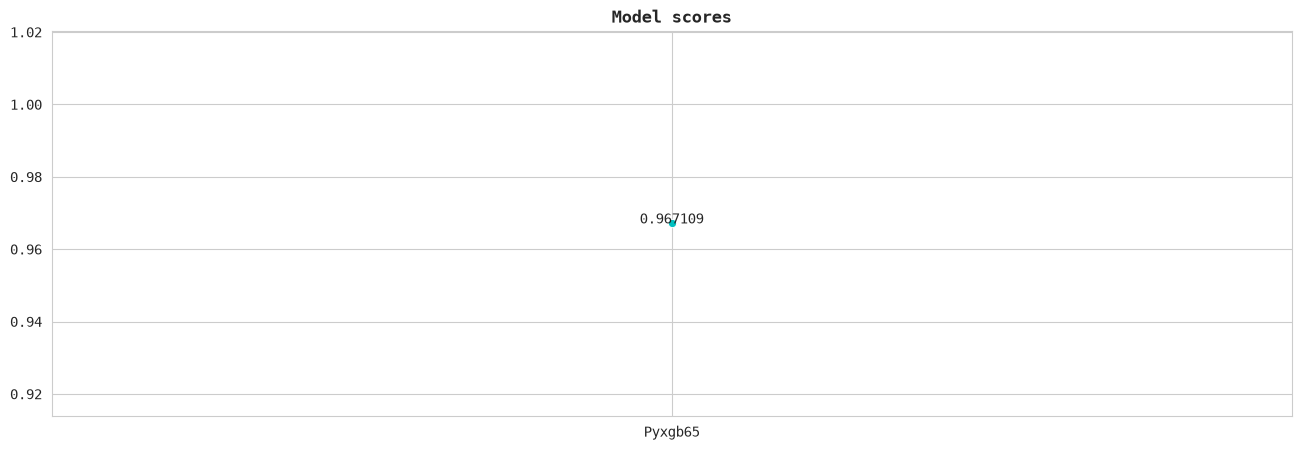

In [39]:
## -- Get Scores --
all_scores = {}

for k, v in all_predictions.items():
    for x, y in v.items():
        if x == "score":
            all_scores[k] = y

plt.figure(figsize=(16, 5))
ax = sns.lineplot(all_scores, marker='o')

# ax.fill_between(range(len(all_model_scores)), all_model_scores.values(), alpha=0.1)
ax.set_title("Model scores", fontweight="semibold")
ax.tick_params('x', rotation=0)
# ax.set_ylim(0.96, 0.968)

add_ = 1e-6
for i, s in enumerate(all_scores.values()):
    ax.text(float(i), s+add_, s, ha="center", va="baseline")

# plt.tight_layout()
plt.show()

## Evaluation and Submission

Pyxgb65_967109 saved!


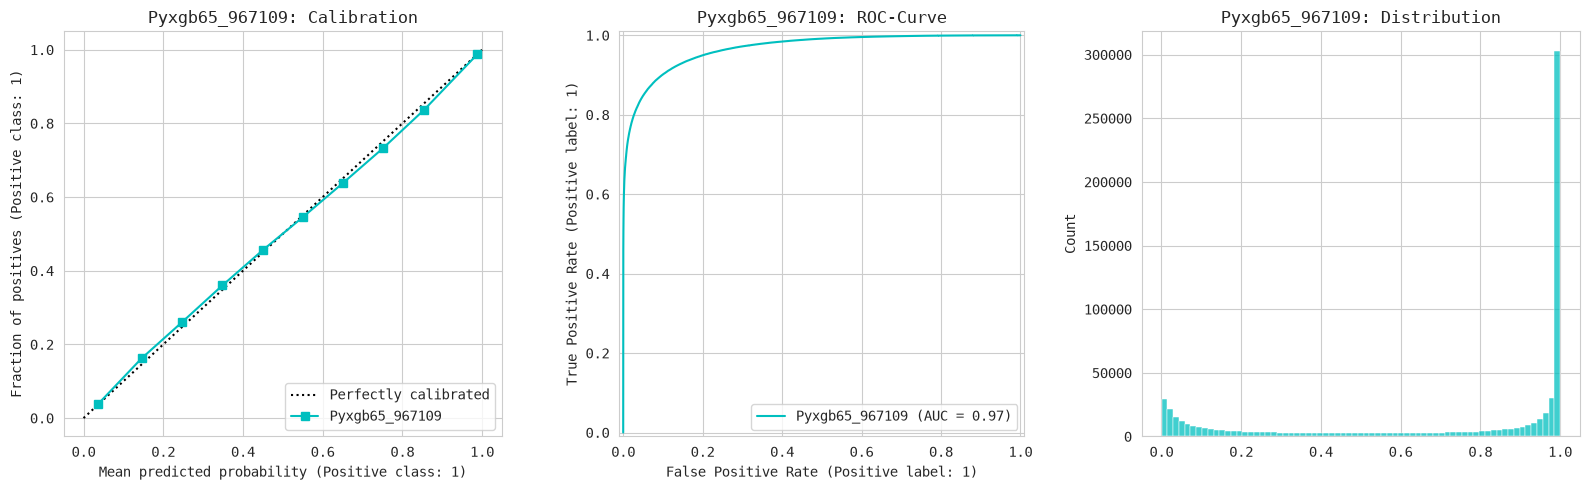

In [40]:
## -- Get oof predictions --
oof_predictions = []

for i, (k, v) in enumerate(all_predictions.items()):
    for key_, data_ in v.items():
        if key_ == "oof_preds":
            ## -- Save oof predictions --
            n = f"{k}_{str(all_scores[k]).split('.')[1]}"
            np.save(f"oof_{n}.npy", data_)
            print(f"{n} saved!")

            ## -- Plot oof distributions --
            _, axs = plt.subplots(1, 3, figsize=(16, 5)) 
            CalibrationDisplay.from_predictions(train_data[TARGET], data_, n_bins=10, name=n, ax=axs[0])
            axs[0].set_title(f"{n}: Calibration")

            RocCurveDisplay.from_predictions(train_data[TARGET], data_, name=n, ax=axs[1])
            axs[1].set_title(f"{n}: ROC-Curve")

            sns.histplot(data_, ax=axs[2])
            axs[2].set_title(f"{n}: Distribution")
            
            plt.tight_layout()
            plt.show()

            print()

In [41]:
## -- Save test predictions/submissions --
model_results = {}

for i, (k, v) in enumerate(all_predictions.items()):
    for j, (x, y) in enumerate(v.items()):
        if x == "test_preds":
            ## -- Base submission file --
            n = f"{k}_{str(all_scores[k]).split('.')[1]}"
            np.save(f"test_{n}.npy", y)

            submit[TARGET] = y
            submit.to_csv(f"submit_{n}.csv", index=False)
            print(f"{CFG["YELLOW"]}{n:20s} {CFG["RESET"]}saved! {y.shape}")

            model_results[n[:-6]] = y

print()
model_results = pd.DataFrame(model_results)
model_results

Pyxgb65_967109       saved! (296302,)



,Pyxgb65_
0,0.960718
1,0.312834
2,0.730744
3,0.247303
4,0.991985
...,...
296297,0.999794
296298,0.988763
296299,0.974981
296300,0.943064


In [42]:
if len(model_results.columns) > 1:
    # display(model_results.corr("spearman"))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    sns.heatmap(model_results.corr("spearman"), annot=True, fmt=".4g", cbar=False, ax=ax1)
    ax1.set_title('Heatmap Correlation (Spearman)', fontsize=14, fontweight='bold')
    
    sns.ecdfplot(data=model_results, linewidth=2, ax=ax2)
    ax2.set_title('CDF Comparison of 5 Probability Distributions', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Probability Value', fontsize=12)
    ax2.set_ylabel('Cumulative Proportion (CDF)', fontsize=12)
    ax2.grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

In [43]:
# ## -- Distribution plots of the last model --
# if USE_CALIBRATION:
#     class_names = [*mapping.keys()]

#     fig, axes = plt.subplots(1, 2, figsize=(16, 5))
#     for i, (ax, preds, title, color) in enumerate([
#         (axes[0], base_preds, f"Base model: {n}", "#73D2DE"),
#         (axes[1], calib_preds, f"Calibrated: {cal_n}", "#FB5607"),
#     ]):
#         counts = [np.sum(preds == i) for i in range(len(np.unique(base_preds)))]
#         ax.bar(class_names, counts, color=color, edgecolor="k")
#         ax.set_title(title, color=["teal", "crimson"][i])
#         ax.set_ylabel("Count")
    
#         for i, c in enumerate(counts):
#             ax.text(i, c+2000, str(c), ha="center", fontsize=10)
    
#     plt.suptitle("Distribution: Base vs Calibrated", fontsize=15, fontweight="semibold")
#     plt.tight_layout()
#     plt.show()
# else:
#     class_names = [*mapping.keys()]
#     counts = [np.sum(base_preds == _) for _ in range(len(np.unique(base_preds)))]

#     fig, axs = plt.subplots(1, 2, figsize=(18, 5))
#     axs[0].bar(class_names, counts, color="#73D2DE", edgecolor="k")
#     axs[0].set_title(f"{n}: Predicted_labels", color="teal")
#     axs[0].set_ylabel("Count")

#     for i, c in enumerate(counts):
#         axs[0].text(i, c+2500, str(c), ha="center", fontsize=10)

#     sns.histplot(p.ravel(), ax=axs[1], color="#FB5607")
#     axs[1].set_title(f"{n}: Distribution", color="crimson")

#     plt.suptitle("Label predictions", fontsize=15, fontweight="semibold")
#     plt.tight_layout()
#     plt.show()

In [44]:
# !rm -r /kaggle/working/